In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Dense, Flatten, Conv2D, MaxPooling2D,
    BatchNormalization, Dropout, Activation,
    RandomFlip, RandomRotation, RandomZoom
)
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [3]:
path=r"C:\Users\LENOVO\Downloads\cifar-10-python(1)\cifar-10-batches-py"

In [6]:
X=[]
y=[]
for i in range(1,6):
    data=pickle.load(
        open(os.path.join(path,"data_batch_" +str(i)),"rb"),
        encoding="bytes"
    )
    X.extend(data[b"data"])
    y.extend(data[b"labels"])

In [7]:
X=np.array(X)
y=np.array(y)
X=X.reshape(-1,3,32,32).transpose(0,2,3,1)

In [8]:
data=pickle.load(
    open(os.path.join(path,"test_batch"),"rb"),
    encoding="bytes"
)
X_test=np.array(data[b"data"])
y_test=np.array(data[b"labels"])
X_test=X_test.reshape(-1,3,32,32).transpose(0,2,3,1)

In [9]:
print("Training data:", X.shape)
print("Training labels:", y.shape)
print("Testing data:", X_test.shape)
print("Testing labels:", y_test.shape)

Training data: (50000, 32, 32, 3)
Training labels: (50000,)
Testing data: (10000, 32, 32, 3)
Testing labels: (10000,)


In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

In [11]:
X_train = X_train.astype("float32") / 255
X_val = X_val.astype("float32") / 255
X_test = X_test.astype("float32") / 255

In [12]:
y_train_cat = to_categorical(y_train, 10)
y_val_cat = to_categorical(y_val, 10)
y_test_cat = to_categorical(y_test, 10)

In [13]:
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

In [14]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


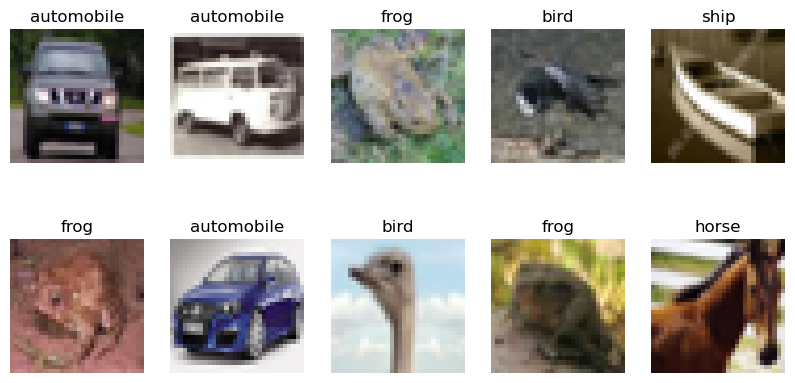

In [15]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.show()

In [16]:
ann=Sequential([
    Input(shape=(32,32,3)),
    Flatten(),
    Dense(512,activation='relu'),
    Dense(256,activation='relu'),
    Dense(10,activation='softmax')
])
ann.compile(optimizer="adam",
            loss="categorical_crossentropy",
            metrics=["accuracy"]
           )
history_ann=ann.fit(
    X_train,y_train_cat,
    epochs=10,
    batch_size=64,
    validation_data=(X_val,y_val_cat)
)
loss, acc_ann = ann.evaluate(X_test, y_test_cat, verbose=0)

print("ANN Accuracy:", round(acc_ann * 100, 2), "%")

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step - accuracy: 0.3201 - loss: 1.8959 - val_accuracy: 0.3670 - val_loss: 1.7561
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.3988 - loss: 1.6837 - val_accuracy: 0.4180 - val_loss: 1.6295
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.4310 - loss: 1.5908 - val_accuracy: 0.4126 - val_loss: 1.6325
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.4497 - loss: 1.5398 - val_accuracy: 0.4450 - val_loss: 1.5558
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.4656 - loss: 1.4964 - val_accuracy: 0.4510 - val_loss: 1.5408
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.4760 - loss: 1.4692 - val_accuracy: 0.4576 - val_loss: 1.5363
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.4855 - loss: 1.4397 - val_accuracy: 0.4550 - val_loss: 1.5395
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.4939 - loss: 1.4165 - 

In [17]:
augmentation=Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])
    

In [18]:
cnn=Sequential([
    Input(shape=(32,32,3)),
    augmentation,
    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])

cnn.compile(optimizer="adam",
            loss="categorical_crossentropy",
            metrics=["accuracy"]
           )
history_cnn=cnn.fit(
    X_train,y_train_cat,
    epochs=10,
    batch_size=64,
    validation_data=(X_val,y_val_cat)
)
loss, acc_cnn = cnn.evaluate(X_test, y_test_cat, verbose=0)
print("CNN Accuracy:", round(acc_cnn * 100, 2), "%")

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 37ms/step - accuracy: 0.4277 - loss: 1.5844 - val_accuracy: 0.5304 - val_loss: 1.3043
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.5279 - loss: 1.3233 - val_accuracy: 0.5436 - val_loss: 1.3135
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.5675 - loss: 1.2244 - val_accuracy: 0.5896 - val_loss: 1.1479
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.5938 - loss: 1.1634 - val_accuracy: 0.6318 - val_loss: 1.0602
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.6048 - loss: 1.1201 - val_accuracy: 0.6414 - val_loss: 1.0337
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.6195 - loss: 1.0822 - val_accuracy: 0.6338 - val_loss: 1.0621
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.6349 - loss: 1.0353 - val_accuracy: 0.6630 - val_loss: 0.9650
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.6388 - loss: 1.0181 - 

In [20]:
cnn_bn=Sequential([
    Input(shape=(32,32,3)),
    augmentation,
    Conv2D(32,(3,3),padding="same"),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2,2)),
    Conv2D(64,(3,3),padding="same"),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128,activation="relu"),
    Dense(10,activation="softmax")
])
cnn_bn.compile(optimizer="adam",
               loss="categorical_crossentropy",
               metrics=["accuracy"])

history_bn=cnn_bn.fit(
    X_train,y_train_cat,
    epochs=10,
    batch_size=64,
    validation_data=(X_val,y_val_cat)
)
loss, acc_bn = cnn_bn.evaluate(X_test, y_test_cat, verbose=0)
print("CNN + Batch Normalization:", round(acc_bn * 100, 2), "%")
           

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 64s 83ms/step - accuracy: 0.4267 - loss: 1.6097 - val_accuracy: 0.5100 - val_loss: 1.3380
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 59s 84ms/step - accuracy: 0.5317 - loss: 1.3023 - val_accuracy: 0.5060 - val_loss: 1.4015
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 82ms/step - accuracy: 0.5714 - loss: 1.2016 - val_accuracy: 0.6066 - val_loss: 1.1055
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 59s 83ms/step - accuracy: 0.5967 - loss: 1.1371 - val_accuracy: 0.5938 - val_loss: 1.1670
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 82ms/step - accuracy: 0.6158 - loss: 1.0903 - val_accuracy: 0.5500 - val_loss: 1.3393
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 57s 81ms/step - accuracy: 0.6272 - loss: 1.0532 - val_accuracy: 0.5646 - val_loss: 1.3429
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 82ms/step - accuracy: 0.6402 - loss: 1.0215 - val_accuracy: 0.5704 - val_loss: 1.3412
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 59s 84ms/step - accuracy: 0.6508 - loss: 0.9909 - 

In [21]:
cnn_dropout=Sequential([
    Input(shape=(32,32,3)),
    augmentation,
    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    Dropout(0.25),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    Dropout(0.25),
    Flatten(),
    Dense(128,activation="relu"),
    Dropout(0.25),
    Dense(10,activation="softmax")
])

cnn_dropout.compile(optimizer="adam",
                    loss="categorical_crossentropy",
                    metrics=["accuracy"]
                   )

history_dropout=cnn_dropout.fit(
    X_train,y_train_cat,
    epochs=10,
    batch_size=64,
    validation_data=(X_val,y_val_cat)
)
loss,acc_dropout=cnn_dropout.evaluate(X_test,y_test_cat,verbose=0)
print("CNN + Dropout:",round(acc_dropout*100,2),"%")
    

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - accuracy: 0.3688 - loss: 1.7287 - val_accuracy: 0.4764 - val_loss: 1.4042
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 40ms/step - accuracy: 0.4763 - loss: 1.4630 - val_accuracy: 0.5070 - val_loss: 1.3764
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5104 - loss: 1.3710 - val_accuracy: 0.5670 - val_loss: 1.2269
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5288 - loss: 1.3220 - val_accuracy: 0.5744 - val_loss: 1.2178
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5424 - loss: 1.2833 - val_accuracy: 0.5948 - val_loss: 1.1192
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5538 - loss: 1.2615 - val_accuracy: 0.6288 - val_loss: 1.0671
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5622 - loss: 1.2303 - val_accuracy: 0.6316 - val_loss: 1.0595
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5730 - loss: 1.2070 - 

ANN : 48.71 %
CNN : 66.7 %
CNN + BatchNorm : 61.32 %
CNN+Dropout : 64.28 %


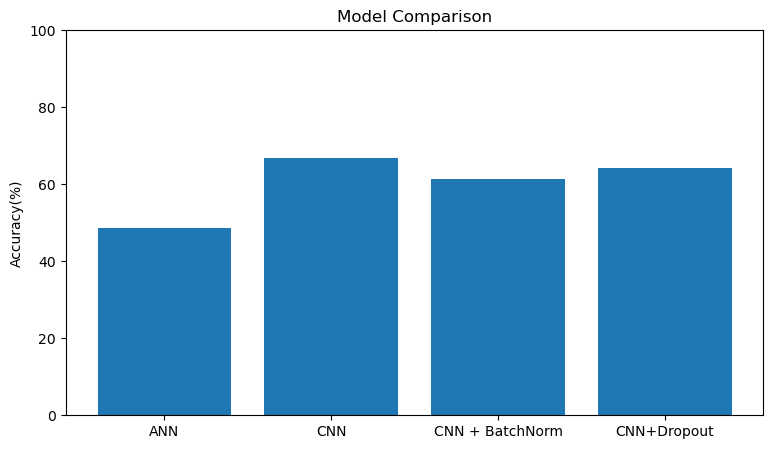

In [22]:
models=["ANN","CNN","CNN + BatchNorm","CNN+Dropout"]
accuracies=[
    acc_ann*100,
    acc_cnn*100,
    acc_bn*100,
    acc_dropout*100
]
for name,acc in zip(models,accuracies):
    print(name,":",round(acc,2),"%")
plt.figure(figsize=(9,5))
plt.bar(models,accuracies)
plt.ylabel("Accuracy(%)")
plt.title("Model Comparison")
plt.ylim(0,100)
plt.show()